In [3]:
%pip install numpy pandas scikit-learn seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 35.9 MB/s  0:00:00s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 37.8 MB/s  0:00:00s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 42.5 MB/s  0:00:00 285.0 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 37.1 MB/s  0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 26.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 29.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 32.6 MB/s  0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 38.6 MB/s  0:00:00s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16/16 [seaborn]5;237m━━ 15/16 [seaborn]earn]
Note: you may need to restart the kernel to use updated packages.


In [4]:
import numpy as np
import pandas as pd

url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'
df = pd.read_csv(url)

cols = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']
df = df[cols]
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

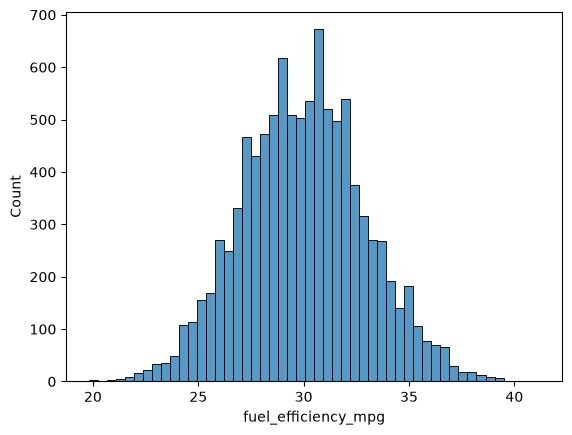

In [5]:
import seaborn as sns
sns.histplot(df.fuel_efficiency_mpg, bins=50)

In [6]:
print(df.isnull().sum())                 # Q1
print(df['horsepower'].median())         # Q2

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64
254.0


In [7]:
base = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']

def split_data(df, seed):
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]
    return df_train, df_val, df_test

def prepare_X(df, fill_value):
    return df[base].fillna(fill_value).values

def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X) + r * np.eye(X.shape[1])
    w_full = np.linalg.inv(XTX).dot(X.T).dot(y)
    return w_full[0], w_full[1:]

def rmse(y, y_pred):
    return np.sqrt(((y - y_pred) ** 2).mean())

In [8]:
#Q3
df_train, df_val, df_test = split_data(df, seed=42)
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values

# 1: Fill zero
X_train = prepare_X(df_train, 0)
w0, w = train_linear_regression_reg(X_train, y_train, r=0)
y_pred = w0 + prepare_X(df_val, 0).dot(w)
print('fill 0   :', round(rmse(y_val, y_pred), 3))

# 2: Fill mean 
mean_hp = df_train.horsepower.mean()
X_train = prepare_X(df_train, mean_hp)
w0, w = train_linear_regression_reg(X_train, y_train, r=0)
y_pred = w0 + prepare_X(df_val, mean_hp).dot(w)
print('fill mean:', round(rmse(y_val, y_pred), 3))

fill 0   : 2.205
fill mean: 2.202


In [9]:
#Q4
X_train = prepare_X(df_train, 0)
X_val = prepare_X(df_val, 0)

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)
    y_pred = w0 + X_val.dot(w)
    print(r, round(rmse(y_val, y_pred), 4))

0 2.2053
0.01 2.2058
0.1 2.2241
1 2.3492
5 2.4094
10 2.4195
100 2.4292


In [10]:
#Q5
scores = []
for seed in range(10):
    df_train, df_val, df_test = split_data(df, seed)
    w0, w = train_linear_regression_reg(prepare_X(df_train, 0), df_train.fuel_efficiency_mpg.values, r=0)
    y_pred = w0 + prepare_X(df_val, 0).dot(w)
    scores.append(rmse(df_val.fuel_efficiency_mpg.values, y_pred))

print(round(np.std(scores), 3))

0.029


In [11]:
#Q6
df_train, df_val, df_test = split_data(df, seed=9)
df_full = pd.concat([df_train, df_val])

w0, w = train_linear_regression_reg(prepare_X(df_full, 0), df_full.fuel_efficiency_mpg.values, r=0.001)
y_pred = w0 + prepare_X(df_test, 0).dot(w)
print(round(rmse(df_test.fuel_efficiency_mpg.values, y_pred), 3))

2.236
